# DYNOC - Dynamic Optimal Clustering
100 random points in 5 dimensions, drawn around 4 close means with uneven group sizes (40, 30, 20, 10).

## Parameters
Change the values here and run all cells again.

In [97]:
import numpy as np
import matplotlib.pyplot as plt

# dataset
seed = 42
means = [[0, 0, 0, 0, 0],
         [3, 3, 3, 3, 3],
         [-3, 3, -3, 3, -3],
         [3, -3, 3, -3, 3]]
sizes = [40, 30, 20, 10]
std = 1.0

# DYNOC
a = 0.9              # extreme point threshold, 1/2 < a < 1
alpha = 1.5          # standard deviation threshold, 1 < alpha < 2
beta = 2             # cluster size threshold, 1 < beta < 3
theta_scale = 1.0    # merging threshold theta_m = theta_scale * D
min_size = 2         # clusters smaller than this are discarded
kmeans_iters = 20
max_iter = 50

In [98]:
np.random.seed(seed)

X = np.vstack([std * np.random.randn(n, len(m)) + m for n, m in zip(sizes, means)])
true_labels = np.repeat(range(len(sizes)), sizes)
print(X.shape)

(100, 5)


In [99]:
np.savetxt("dataset.txt", np.column_stack([X, true_labels]),
           fmt=["%.4f"] * X.shape[1] + ["%d"], header="x1 x2 x3 x4 x5 group")

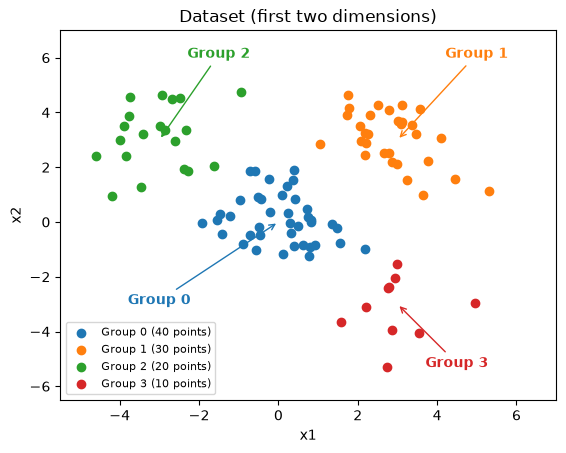

In [100]:
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
label_pos = [(-3, -3), (5, 6), (-1.5, 6), (4.5, -5.3)]

for k in range(len(sizes)):
    pts = X[true_labels == k]
    plt.scatter(pts[:, 0], pts[:, 1], color=colors[k], label=f"Group {k} ({sizes[k]} points)")
    plt.annotate(f"Group {k}", xy=means[k][:2], xytext=label_pos[k], ha="center",
                 color=colors[k], fontweight="bold", arrowprops=dict(arrowstyle="->", color=colors[k]))

plt.xlim(-5.5, 7)
plt.ylim(-6.5, 7)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Dataset (first two dimensions)")
plt.legend(loc="lower left", fontsize=8)
plt.show()

## Initial centres (extreme point approach)

In [101]:
def initial_centres(X):
    z0 = X.mean(axis=0)
    D0 = np.mean(np.linalg.norm(X - z0, axis=1))

    # reference point: the one with the largest component
    ref = X[np.abs(X).max(axis=1).argmax()]
    centres = [ref]

    for x in X:
        if all(np.linalg.norm(x - c) > a * D0 for c in centres):
            centres.append(x)

    return np.array(centres)

centres = initial_centres(X)
D0 = np.mean(np.linalg.norm(X - X.mean(axis=0), axis=1))

print("D0 =", round(D0, 2))
print("Threshold a*D0 =", round(a * D0, 2))
print("Initial centres:", len(centres))

for c in centres:
    i = np.where((X == c).all(axis=1))[0][0]
    print(f"  point {i} from true group {true_labels[i]}")

D0 = 4.95
Threshold a*D0 = 4.46
Initial centres: 6
  point 41 from true group 1
  point 0 from true group 0
  point 40 from true group 1
  point 52 from true group 1
  point 70 from true group 2
  point 90 from true group 3


## Step 2: K-means refinement

In [102]:
def assign(X, centres):
    dist = np.linalg.norm(X[:, None] - centres[None], axis=2)
    return dist.argmin(axis=1)


def kmeans(X, centres):
    for _ in range(kmeans_iters):
        labels = assign(X, centres)
        counts = np.bincount(labels, minlength=len(centres))
        centres = centres[counts >= min_size]   # discard extremely small clusters
        labels = assign(X, centres)
        centres = np.array([X[labels == k].mean(axis=0) for k in range(len(centres))])
    return centres, assign(X, centres)

## Steps 3-6: interset / intraset distances and performance index

In [103]:
def cluster_stats(X, centres, labels):
    sigma = np.array([X[labels == k].std(axis=0) for k in range(len(centres))])
    N = np.bincount(labels, minlength=len(centres))
    Dj = np.sqrt(2 * (sigma ** 2).sum(axis=1))
    Dij = np.linalg.norm(centres[:, None] - centres[None], axis=2)
    return sigma, N, Dj, Dij


def performance_index(Dj, Dij):
    min_Dij = Dij[np.triu_indices(len(Dj), k=1)].min()
    return min_Dij / Dj.max()

## Step 7: Split a large cluster

In [104]:
def split(X, centres, labels):
    sigma, N, Dj, Dij = cluster_stats(X, centres, labels)
    Nc = len(centres)
    D = (N * Dj).sum() / len(X)

    candidates = []
    for j in range(Nc):
        if sigma[j].max() > alpha * sigma[j].mean() or N[j] > beta * len(X) / Nc or Dj[j] > D:
            candidates.append(j)

    if not candidates:
        return centres

    j = max(candidates, key=lambda k: Dj[k])
    gamma = np.delete(Dij[j], j).min() / (2 * Dj[j])

    c = np.zeros(X.shape[1])
    c[sigma[j].argmax()] = gamma * Dj[j]

    others = np.delete(centres, j, axis=0)
    return np.vstack([others, centres[j] + c, centres[j] - c])

## Step 8: Merge small clusters

In [105]:
def merge(X, centres, labels, theta_m):
    sigma, N, Dj, Dij = cluster_stats(X, centres, labels)
    np.fill_diagonal(Dij, np.inf)

    i, j = np.unravel_index(Dij.argmin(), Dij.shape)
    if Dij[i, j] >= theta_m:
        return centres

    z_new = (N[i] * centres[i] + N[j] * centres[j]) / (N[i] + N[j])
    others = np.delete(centres, [i, j], axis=0)
    return np.vstack([others, z_new])

## Step 9: Iterate

In [106]:
def dynoc(X):
    centres = initial_centres(X)
    history = []
    prev_lam = -np.inf
    best_lam = -np.inf

    for _ in range(max_iter):
        # steps 2-6
        centres, labels = kmeans(X, centres)
        sigma, N, Dj, Dij = cluster_stats(X, centres, labels)
        lam = performance_index(Dj, Dij)

        # stop if splitting and merging start going in circles
        if (len(centres), round(lam, 6)) in history:
            break
        history.append((len(centres), round(lam, 6)))

        if lam > best_lam:
            best_lam, best_centres, best_labels = lam, centres, labels

        # lambda increased, or the last peak was not the global maximum -> step 7
        if lam > prev_lam or prev_lam < best_lam:
            prev_lam = lam
            centres = split(X, centres, labels)
            continue

        # last peak is the global maximum -> check merging condition (step 8)
        centres, labels = best_centres, best_labels
        sigma, N, Dj, Dij = cluster_stats(X, centres, labels)
        theta_m = theta_scale * (N * Dj).sum() / len(X)
        merged = merge(X, centres, labels, theta_m)
        if len(merged) == len(centres):
            break
        prev_lam = -np.inf
        centres = merged

    return best_centres, best_labels, history

## Results

In [107]:
centres, labels, history = dynoc(X)

for Nc, lam in history:
    print(f"Nc = {Nc}, lambda = {lam:.3f}")

print("\nOptimal number of clusters:", len(centres))
print("Cluster sizes:", np.bincount(labels))

Nc = 6, lambda = 0.728
Nc = 7, lambda = 0.730
Nc = 8, lambda = 0.727
Nc = 6, lambda = 0.877
Nc = 7, lambda = 0.727
Nc = 5, lambda = 0.984
Nc = 6, lambda = 0.684

Optimal number of clusters: 5
Cluster sizes: [40 20  3  7 30]


In [108]:
sigma, N, Dj, Dij = cluster_stats(X, centres, labels)
theta_m = theta_scale * (N * Dj).sum() / len(X)
np.fill_diagonal(Dij, np.inf)
i, j = np.unravel_index(Dij.argmin(), Dij.shape)

print("Best lambda:", max(lam for _, lam in history))
print("theta_m =", round(theta_m, 2))
print(f"Closest clusters: {i} and {j}, distance = {Dij[i, j]:.2f}")
print("Intraset distances Dj:", Dj.round(2))

print("\nCluster  size  points from each true group")
for k in range(len(centres)):
    print(f"{k:>7}  {N[k]:>4}  {np.bincount(true_labels[labels == k], minlength=len(sizes))}")

Best lambda: 0.983756
theta_m = 2.97
Closest clusters: 2 and 3, distance = 3.11
Intraset distances Dj: [2.91 3.17 2.43 2.46 3.09]

Cluster  size  points from each true group
      0    40  [40  0  0  0]
      1    20  [ 0  0 20  0]
      2     3  [0 0 0 3]
      3     7  [0 0 0 7]
      4    30  [ 0 30  0  0]


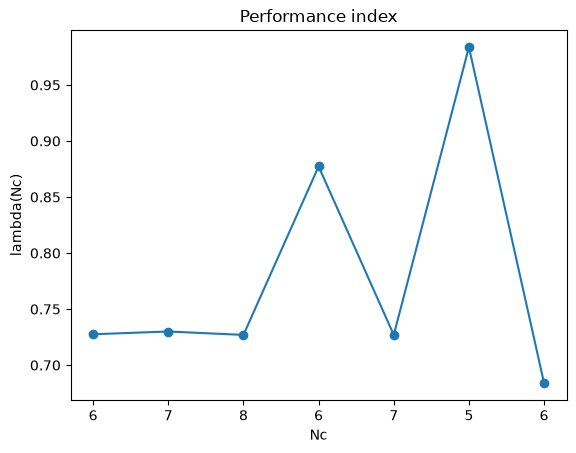

In [109]:
Ncs, lams = zip(*history)
plt.plot(range(len(lams)), lams, marker="o")
plt.xticks(range(len(lams)), Ncs)
plt.xlabel("Nc")
plt.ylabel("lambda(Nc)")
plt.title("Performance index")
plt.show()

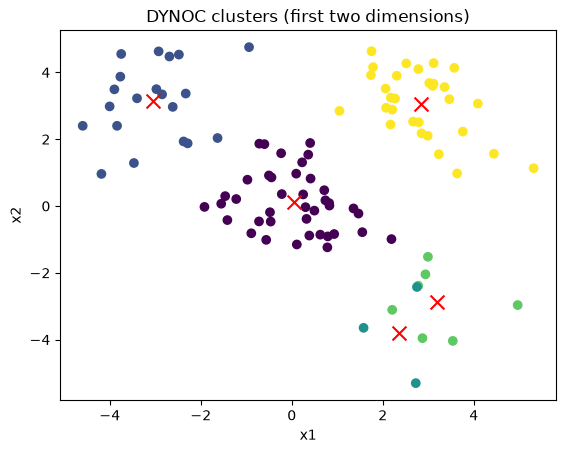

In [110]:
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.scatter(centres[:, 0], centres[:, 1], c="red", marker="x", s=100)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("DYNOC clusters (first two dimensions)")
plt.show()